# So sánh định lượng Baseline (A0) và mô hình cuối (v4)

Nội dung trình bày protocol đánh giá và kết quả so sánh hai mô hình phát hiện mệnh giá trên cùng điều kiện đo. Trọng số và tệp xuất được đọc từ thư mục gốc dự án (`notebooks/*_exports`, `notebooks/compare_exports`).


## Mục tiêu và protocol đánh giá

Mục tiêu là so sánh khách quan mô hình cơ sở và mô hình cải tiến theo cùng protocol, sau đó phân tích điểm mạnh, hạn chế và hàm ý thực nghiệm.

| Mô hình | Checkpoint | Vai trò |
|---------|------------|---------|
| **Baseline A0** | `baseline_exports/yolov8n_baseline_best.pt` | Mốc tham chiếu (YOLOv8n, tăng cường mặc định) |
| **Final v4** | `v4_exports/yolov8s_v4_best.pt` | Bản cải tiến (YOLOv8s; tăng cường mạnh; xoay/oversample; ảnh camera thực tế) |

**Protocol đo**
1. Tập đánh giá: `datasets/fair_eval_hardmix` — 40 ảnh chụp thực đã chuẩn hóa bbox.
2. Thành phần: **16 ảnh Hard** (lóa sáng, cong tờ, nền rối, hắt sáng, xoay/lật) và **24 ảnh Normal** lấy ngẫu nhiên với seed cố định ($=42$).
3. Đánh giá chính: `imgsz=640`, `conf=0.25` trên toàn bộ 40 ảnh.
4. Phân tích bổ sung: tách nhóm **Hard** và **Normal**; đo thêm v4 ở `imgsz=800` (cấu hình suy luận thực tế).
5. Checkpoint được chọn trong quá trình huấn luyện trên Roboflow; `fair_eval_hardmix` là tập đánh giá độc lập sau khi khóa cấu hình.


## 1. Thư viện và cấu hình thực nghiệm


In [1]:
from __future__ import annotations


from pathlib import Path

def _resolve_project() -> Path:
    for cand in [Path.cwd().parents[1], Path.cwd().parent,
                 Path('/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam')]:
        if (cand / 'notebooks' / 'compare_exports').exists():
            return cand.resolve()
    return Path.cwd().resolve()

PROJECT = _resolve_project()
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import yaml
from ultralytics import YOLO

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Gốc dự án + thư mục notebooks gốc (weights / compare_exports)
PROJECT_DIR = PROJECT
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
EXPORT_DIR = NOTEBOOK_DIR / "compare_exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
# Đồng bộ bản sao chỉ số sang report/exports
REPORT_EXPORT = PROJECT_DIR / "report" / "exports"
REPORT_EXPORT.mkdir(parents=True, exist_ok=True)

# Tập đánh giá công bằng: 16 Hard + 24 Normal (ảnh chụp thực)
DATA_DIR = PROJECT_DIR / "datasets" / "fair_eval_hardmix"
DATA_YAML = DATA_DIR / "data.yaml"
DATA_HARD_YAML = DATA_DIR / "data_hard.yaml"
DATA_NORMAL_YAML = DATA_DIR / "data_normal.yaml"
assert DATA_YAML.exists(), f"Thiếu tập đánh giá: {DATA_YAML}"
assert DATA_HARD_YAML.exists() and DATA_NORMAL_YAML.exists()

BASE_PT = NOTEBOOK_DIR / "baseline_exports" / "yolov8n_baseline_best.pt"
FINAL_PT = NOTEBOOK_DIR / "v4_exports" / "yolov8s_v4_best.pt"
assert BASE_PT.exists(), BASE_PT
assert FINAL_PT.exists(), FINAL_PT

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)
CLASS_NAMES = list(data_cfg["names"])
# Đảm bảo path trong yaml đúng máy hiện tại
data_cfg["path"] = str(DATA_DIR.resolve())
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False, allow_unicode=True)

manifest = pd.read_csv(DATA_DIR / "manifest.csv")
N_HARD = int((manifest["difficulty"] == "hard").sum())
N_NORMAL = int((manifest["difficulty"] == "normal").sum())

DEVICE = 0 if torch.cuda.is_available() else "cpu"
FAIR_IMGSZ = 640          # protocol so sánh chính
DEPLOY_IMGSZ = 800        # imgsz train/deploy của v4
VAL_SPLIT = "val"         # fair_eval: train/val/test cùng trỏ images/
TEST_SPLIT = "test"

print("DEVICE :", DEVICE)
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
print("DATA   :", DATA_YAML)
print(f"EVAL   : fair_eval_hardmix | Hard={N_HARD} | Normal={N_NORMAL} | total={len(manifest)}")
print("BASE   :", BASE_PT)
print("FINAL  :", FINAL_PT)
print("Classes:", CLASS_NAMES)


DEVICE : 0
GPU    : NVIDIA GeForce RTX 5060
DATA   : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/data.yaml
EVAL   : fair_eval_hardmix | Hard=16 | Normal=24 | total=40
BASE   : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/baseline_exports/yolov8n_baseline_best.pt
FINAL  : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/v4_exports/yolov8s_v4_best.pt
Classes: ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']


## 2. Hàm đánh giá và trích xuất chỉ số


In [2]:
def extract_metrics(metrics, class_names=CLASS_NAMES) -> dict:
    box = metrics.box
    out = {
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
        "precision": float(box.mp),
        "recall": float(box.mr),
    }
    # F1 macro gần đúng từ P/R tổng
    p, r = out["precision"], out["recall"]
    out["f1"] = float(0.0 if (p + r) == 0 else 2 * p * r / (p + r))

    if getattr(box, "ap50", None) is not None:
        ap50 = np.array(box.ap50).reshape(-1)
        for i, name in enumerate(class_names):
            if i < len(ap50):
                out[f"AP50_{name}"] = float(ap50[i])
    return out


def run_val(
    weights: Path,
    split: str,
    imgsz: int,
    conf: float = 0.25,
    name: str = "model",
    data_yaml: Path | None = None,
) -> dict:
    model = YOLO(str(weights))
    metrics = model.val(
        data=str(data_yaml or DATA_YAML),
        split=split,
        imgsz=imgsz,
        conf=conf,
        device=DEVICE,
        plots=False,
        verbose=False,
        project=str(EXPORT_DIR / "ultralytics_runs"),
        name=name.replace(" ", "_")[:40],
        exist_ok=True,
    )
    out = extract_metrics(metrics)
    out["model"] = name
    out["split"] = split
    out["imgsz"] = imgsz
    out["conf"] = conf
    return out


print("Các hàm đánh giá đã sẵn sàng.")


Các hàm đánh giá đã sẵn sàng.


## 3. Chỉ số lưu trong quá trình huấn luyện (tham chiếu)

Các giá trị dưới đây phản ánh theo dõi trên validation Roboflow lúc huấn luyện. Chúng mang tính tham chiếu lịch sử học và không thay thế bảng so sánh trên `fair_eval_hardmix`.


In [3]:
rows_saved = []
for label, csv_path in [
    ("A0 baseline", NOTEBOOK_DIR / "baseline_exports" / "baseline_val_metrics.csv"),
    ("v2", NOTEBOOK_DIR / "v2_exports" / "v2_val_metrics.csv"),
    ("v3", NOTEBOOK_DIR / "v3_exports" / "v3_val_metrics.csv"),
    ("v4 final", NOTEBOOK_DIR / "v4_exports" / "v4_val_metrics.csv"),
]:
    if csv_path.exists():
        d = pd.read_csv(csv_path).iloc[0].to_dict()
        rows_saved.append({
            "model": label,
            "val_mAP50": d.get("val_mAP50"),
            "val_mAP50-95": d.get("val_mAP50-95"),
            "val_precision": d.get("val_precision"),
            "val_recall": d.get("val_recall"),
            "source": str(csv_path.name),
        })

saved_df = pd.DataFrame(rows_saved)
display(saved_df)
saved_df.to_csv(EXPORT_DIR / "saved_train_val_metrics_history.csv", index=False)

print(
    "Ghi chú: chỉ số được ghi nhận trong lúc huấn luyện; imgsz/conf có thể khác protocol so sánh chính.\n"
    "Bảng so sánh chính thức nằm ở mục 3–4 (cùng protocol)."
)


,model,val_mAP50,val_mAP50-95,val_precision,val_recall,source
0,A0 baseline,0.994649,0.931480,0.989089,0.995300,baseline_val_metrics.csv
1,v2,0.993818,0.866929,0.987712,0.998943,v2_val_metrics.csv
2,v3,0.994854,0.861327,0.990711,0.998683,v3_val_metrics.csv
3,v4 final,0.993986,0.890809,0.993468,0.997710,v4_val_metrics.csv


Ghi chú: chỉ số được ghi nhận trong lúc huấn luyện; imgsz/conf có thể khác protocol so sánh chính.
Bảng so sánh chính thức nằm ở mục 3–4 (cùng protocol).


## 4. Đánh giá trên `fair_eval_hardmix` (`imgsz=640`)

Tập gồm **40 ảnh chụp thực** (16 Hard và 24 Normal). Đây là bảng so sánh chính giữa baseline và mô hình cuối trong điều kiện gần miền triển khai. Valid/test Roboflow, do gần bão hòa chỉ số từ baseline, chỉ được dùng như tham chiếu miền studio.


Đánh giá baseline trên toàn bộ fair_eval...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8195.2±2657.1 MB/s, size: 2946.2 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 15.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.3it/s 1.3s0.9s
                   all         40         88      0.708      0.435      0.399      0.325
Speed: 0.3ms preprocess, 2.6ms inference, 0.0ms loss, 0.4ms postprocess per image
Đánh giá mô hình cuối (v4) trên toàn bộ fair_eval...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 1

,model,split,imgsz,conf,mAP50,mAP50-95,precision,recall,f1
0,A0 YOLOv8n baseline,val,640,0.25,0.3994,0.3254,0.7080,0.4348,0.5387
1,v4 YOLOv8s final,val,640,0.25,0.9293,0.6440,0.9206,0.9127,0.9167


Chênh lệch Final − Baseline (toàn bộ fair_eval, imgsz=640):
  delta_mAP50: +0.5298
  delta_mAP50-95: +0.3185
  delta_precision: +0.2127
  delta_recall: +0.4779
  delta_f1: +0.3779


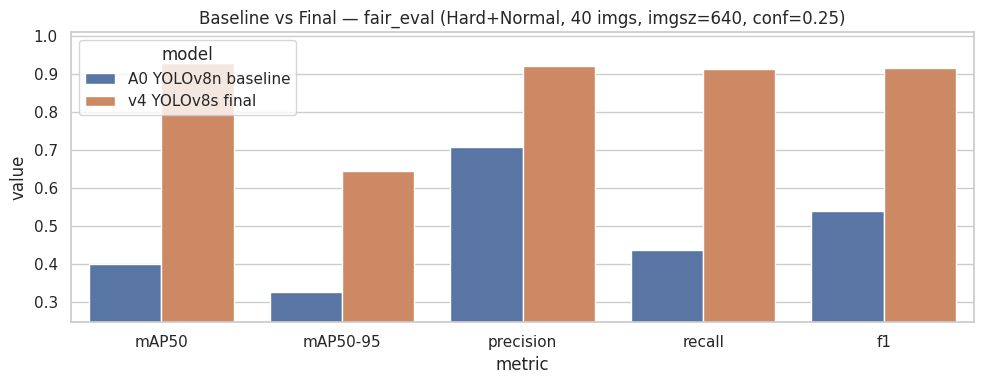

In [4]:
EVAL_CONF = 0.25  # conf cố định khi so backbone/data recipe

print("Đánh giá baseline trên toàn bộ fair_eval...")
base_val = run_val(BASE_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="A0 YOLOv8n baseline")
print("Đánh giá mô hình cuối (v4) trên toàn bộ fair_eval...")
final_val = run_val(FINAL_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="v4 YOLOv8s final")

val_cmp = pd.DataFrame([base_val, final_val])[
    ["model", "split", "imgsz", "conf", "mAP50", "mAP50-95", "precision", "recall", "f1"]
]
display(val_cmp.round(4))
val_cmp.to_csv(EXPORT_DIR / "fair_val_compare_imgsz640.csv", index=False)

# Delta
delta = {
    "delta_mAP50": final_val["mAP50"] - base_val["mAP50"],
    "delta_mAP50-95": final_val["mAP50-95"] - base_val["mAP50-95"],
    "delta_precision": final_val["precision"] - base_val["precision"],
    "delta_recall": final_val["recall"] - base_val["recall"],
    "delta_f1": final_val["f1"] - base_val["f1"],
}
print("Chênh lệch Final − Baseline (toàn bộ fair_eval, imgsz=640):")
for k, v in delta.items():
    print(f"  {k}: {v:+.4f}")

melt = val_cmp.melt(
    id_vars=["model"],
    value_vars=["mAP50", "mAP50-95", "precision", "recall", "f1"],
    var_name="metric",
    value_name="value",
)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=melt, x="metric", y="value", hue="model", ax=ax)
ymin = max(0.0, float(melt["value"].min()) - 0.08)
ax.set_ylim(ymin, 1.01)
ax.set_title("Baseline vs Final — fair_eval (Hard+Normal, 40 imgs, imgsz=640, conf=0.25)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_val_compare_overview.png", dpi=150, bbox_inches="tight")
plt.show()


### 4.1. AP50 theo từng mệnh giá


model,class,A0 baseline,v4 final,delta_final_minus_base
0,1000,0.4950,0.9950,0.5000
1,10000,0.1978,0.8606,0.6628
2,100000,0.5250,0.8779,0.3529
3,2000,0.0000,0.9950,0.9950
4,20000,0.3743,0.8350,0.4607
5,200000,0.5250,0.8850,0.3600
6,5000,0.3750,0.9950,0.6200
7,50000,0.2079,0.9250,0.7171
8,500000,0.8950,0.9950,0.1000


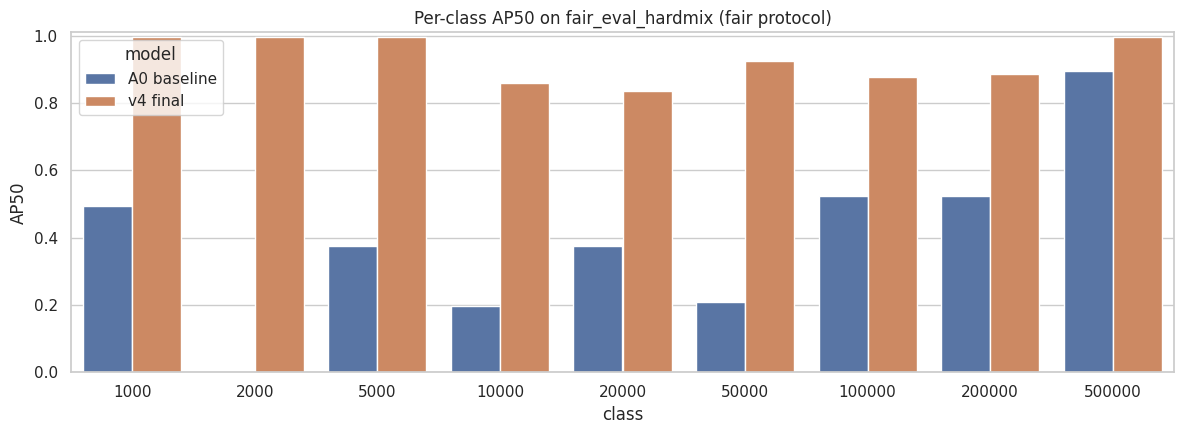

Delta AP50 trên nhóm mệnh giá dễ nhầm trong điều kiện thực:


model,class,A0 baseline,v4 final,delta_final_minus_base
1,10000,0.1978,0.8606,0.6628
2,100000,0.5250,0.8779,0.3529
4,20000,0.3743,0.8350,0.4607
5,200000,0.5250,0.8850,0.3600
6,5000,0.3750,0.9950,0.6200
7,50000,0.2079,0.9250,0.7171
8,500000,0.8950,0.9950,0.1000


In [5]:
def per_class_ap_table(metrics_dict: dict, model_name: str) -> pd.DataFrame:
    rows = []
    for name in sorted(CLASS_NAMES, key=lambda x: int(x)):
        rows.append({"model": model_name, "class": name, "AP50": metrics_dict.get(f"AP50_{name}")})
    return pd.DataFrame(rows)


pc = pd.concat([
    per_class_ap_table(base_val, "A0 baseline"),
    per_class_ap_table(final_val, "v4 final"),
], ignore_index=True)

pc_pivot = pc.pivot(index="class", columns="model", values="AP50").reset_index()
pc_pivot["delta_final_minus_base"] = pc_pivot["v4 final"] - pc_pivot["A0 baseline"]
display(pc_pivot.round(4))
pc_pivot.to_csv(EXPORT_DIR / "fair_val_AP50_per_class.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=pc, x="class", y="AP50", hue="model", ax=ax,
            order=sorted(CLASS_NAMES, key=lambda x: int(x)))
ymin = max(0.0, float(pc["AP50"].dropna().min()) - 0.08) if pc["AP50"].notna().any() else 0.0
ax.set_ylim(ymin, 1.01)
ax.set_title("Per-class AP50 on fair_eval_hardmix (fair protocol)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_val_AP50_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

focus = ["5000", "20000", "200000", "100000", "500000", "10000", "50000"]
print("Delta AP50 trên nhóm mệnh giá dễ nhầm trong điều kiện thực:")
display(pc_pivot[pc_pivot["class"].isin(focus)].round(4))


## 5. Phân tích theo độ khó: Hard và Normal

Cùng protocol `imgsz=640` và `conf=0.25`. Nhóm **Hard** gồm 16 ảnh thực ở điều kiện khó (lóa sáng, cong tờ, nền rối, xoay/lật); nhóm **Normal** gồm 24 ảnh thực ở điều kiện thuận lợi hơn. Việc tách nhóm cho phép định lượng mức suy giảm theo miền khó và mức cải thiện tương ứng của mô hình cuối.


Đánh giá nhóm Hard...
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3937.1±870.9 MB/s, size: 188.6 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/hard/labels.cache... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 3.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 11.6it/s 0.1s
                   all         16         25      0.389       0.25      0.189     0.0946
Speed: 0.1ms preprocess, 1.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (pin

,subset,n_images,model,imgsz,conf,mAP50,mAP50-95,precision,recall,f1
0,Hard,16,A0 baseline,640,0.25,0.1889,0.0946,0.3895,0.2500,0.3045
1,Hard,16,v4 final,640,0.25,0.8747,0.5993,0.9229,0.8829,0.9024
2,Normal,24,A0 baseline,640,0.25,0.5732,0.5058,0.8518,0.5980,0.7027
3,Normal,24,v4 final,640,0.25,0.9554,0.7018,0.9359,0.9251,0.9305


,model,selected_by,all_mAP50,all_mAP50-95,hard_mAP50,hard_mAP50-95,normal_mAP50,hard_P,hard_R,hard_F1,note
0,Baseline YOLOv8n (A0),val during train,0.3994,0.3254,0.1889,0.0946,0.5732,0.3895,0.2500,0.3045,mốc
1,Final YOLOv8s v4,val during iterative improve,0.9293,0.6440,0.8747,0.5993,0.9554,0.9229,0.8829,0.9024,aug + capacity + real-cam data


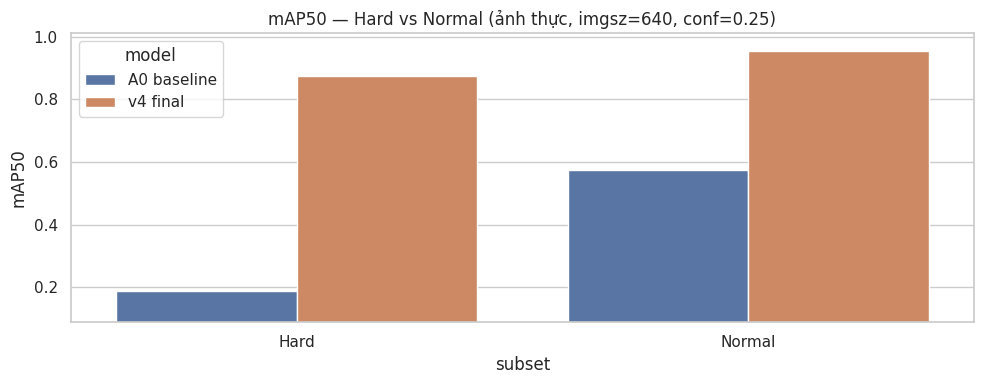

Δ Hard mAP50 (final−base): +0.6858
Δ Normal mAP50 (final−base): +0.3822


In [6]:
print("Đánh giá nhóm Hard...")
base_hard = run_val(BASE_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="A0 baseline", data_yaml=DATA_HARD_YAML)
final_hard = run_val(FINAL_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="v4 final", data_yaml=DATA_HARD_YAML)

print("Đánh giá nhóm Normal...")
base_normal = run_val(BASE_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="A0 baseline", data_yaml=DATA_NORMAL_YAML)
final_normal = run_val(FINAL_PT, VAL_SPLIT, FAIR_IMGSZ, conf=EVAL_CONF, name="v4 final", data_yaml=DATA_NORMAL_YAML)

base_test, final_test = base_hard, final_hard

subgroup = pd.DataFrame([
    {**base_hard, "subset": "Hard", "n_images": N_HARD},
    {**final_hard, "subset": "Hard", "n_images": N_HARD},
    {**base_normal, "subset": "Normal", "n_images": N_NORMAL},
    {**final_normal, "subset": "Normal", "n_images": N_NORMAL},
])[["subset", "n_images", "model", "imgsz", "conf", "mAP50", "mAP50-95", "precision", "recall", "f1"]]
display(subgroup.round(4))
subgroup.to_csv(EXPORT_DIR / "fair_hard_vs_normal_compare.csv", index=False)

report_table = pd.DataFrame([
    {
        "model": "Baseline YOLOv8n (A0)",
        "selected_by": "val during train",
        "all_mAP50": base_val["mAP50"],
        "all_mAP50-95": base_val["mAP50-95"],
        "hard_mAP50": base_hard["mAP50"],
        "hard_mAP50-95": base_hard["mAP50-95"],
        "normal_mAP50": base_normal["mAP50"],
        "hard_P": base_hard["precision"],
        "hard_R": base_hard["recall"],
        "hard_F1": base_hard["f1"],
        "note": "mốc",
    },
    {
        "model": "Final YOLOv8s v4",
        "selected_by": "val during iterative improve",
        "all_mAP50": final_val["mAP50"],
        "all_mAP50-95": final_val["mAP50-95"],
        "hard_mAP50": final_hard["mAP50"],
        "hard_mAP50-95": final_hard["mAP50-95"],
        "normal_mAP50": final_normal["mAP50"],
        "hard_P": final_hard["precision"],
        "hard_R": final_hard["recall"],
        "hard_F1": final_hard["f1"],
        "note": "aug + capacity + real-cam data",
    },
])
display(report_table.round(4))
report_table.to_csv(EXPORT_DIR / "report_table_baseline_vs_final.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=subgroup, x="subset", y="mAP50", hue="model", ax=ax)
ymin = max(0.0, float(subgroup["mAP50"].min()) - 0.1)
ax.set_ylim(ymin, 1.01)
ax.set_title("mAP50 — Hard vs Normal (ảnh thực, imgsz=640, conf=0.25)")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_test_compare_overview.png", dpi=150, bbox_inches="tight")
plt.show()

print("Δ Hard mAP50 (final−base):", f"{final_hard['mAP50'] - base_hard['mAP50']:+.4f}")
print("Δ Normal mAP50 (final−base):", f"{final_normal['mAP50'] - base_normal['mAP50']:+.4f}")


### 5.1. Mô hình cuối ở kích thước suy luận `imgsz=800`


In [7]:
final_val_800 = run_val(FINAL_PT, VAL_SPLIT, DEPLOY_IMGSZ, conf=EVAL_CONF, name="v4 final@800")
final_hard_800 = run_val(FINAL_PT, VAL_SPLIT, DEPLOY_IMGSZ, conf=EVAL_CONF, name="v4 final@800", data_yaml=DATA_HARD_YAML)
final_test_800 = final_hard_800
deploy_df = pd.DataFrame([
    {"setting": "v4 fair@640 ALL", **{k: final_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 deploy@800 ALL", **{k: final_val_800[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 fair@640 Hard", **{k: final_hard[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
    {"setting": "v4 deploy@800 Hard", **{k: final_hard_800[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]}},
])
display(deploy_df.round(4))
deploy_df.to_csv(EXPORT_DIR / "final_640_vs_800.csv", index=False)


Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7425.6±1546.7 MB/s, size: 2025.4 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 15.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.1it/s 1.4s0.9s
                   all         40         88      0.912      0.851      0.861      0.623
Speed: 0.4ms preprocess, 6.1ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read

,setting,mAP50,mAP50-95,precision,recall,f1
0,v4 fair@640 ALL,0.9293,0.6440,0.9206,0.9127,0.9167
1,v4 deploy@800 ALL,0.8607,0.6227,0.9124,0.8515,0.8809
2,v4 fair@640 Hard,0.8747,0.5993,0.9229,0.8829,0.9024
3,v4 deploy@800 Hard,0.7739,0.5128,0.8642,0.7740,0.8166


## 6. Lựa chọn ngưỡng tin cậy theo chi phí lỗi

Điểm tin cậy của YOLO điều khiển cân bằng Precision–Recall. Trên toàn bộ `fair_eval_hardmix`, ngưỡng $\tau$ được quét để tối thiểu hóa hàm chi phí xấp xỉ:

$$
\mathrm{Cost}(\tau)= c_{FP}\,(1-P(\tau)) + c_{FN}\,(1-R(\tau)).
$$

Với bài toán kiểm đếm, bỏ sót được xem là đắt hơn báo nhầm nên chọn $c_{FN}=3$, $c_{FP}=1$. Sau khi xác định $\tau^*$ cho mô hình cuối, chỉ số được đo lại trên nhóm Hard.


Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6602.8±1615.1 MB/s, size: 2473.9 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.3it/s 1.3s0.6s
                   all         40         88      0.708      0.435      0.444      0.357
Speed: 0.2ms preprocess, 1.7ms inference, 0.0ms loss, 0.4ms postprocess per image
A0 baseline conf=0.05 | P=0.708 R=0.435 cost=1.9877
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs


,model,conf,precision,recall,f1,mAP50,cost_proxy
2,A0 baseline,0.15,0.643147,0.492118,0.557587,0.423890,1.880499
8,v4 final,0.45,0.942992,0.911246,0.926847,0.905944,0.323270


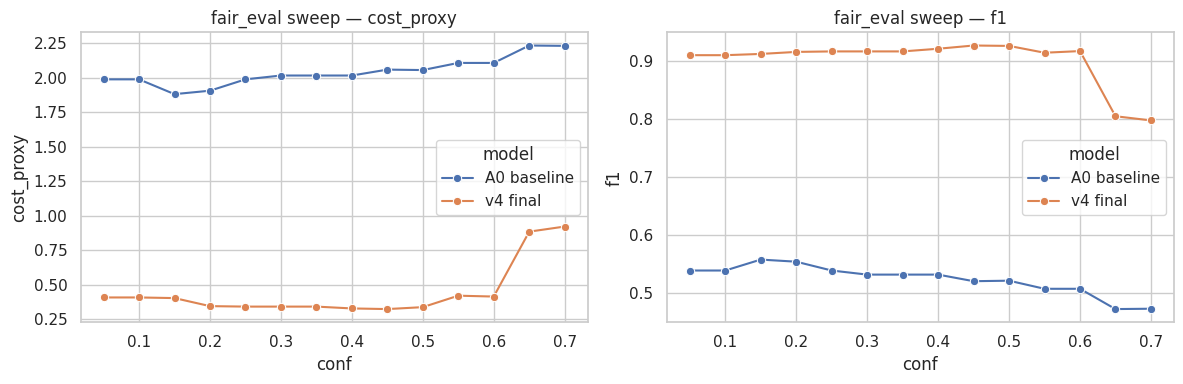


Áp dụng τ*=0.45 của mô hình cuối trên nhóm Hard
Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7144.8±1584.1 MB/s, size: 191.3 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/fair_eval_hardmix/hard/labels.cache... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 5.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 9.1it/s 0.1s
                   all         16         25      0.972      0.861      0.847      0.578
Speed: 0.1ms preprocess, 2.7ms inference, 0.0ms loss, 0.4ms postprocess per image


,model,conf,mAP50,precision,recall,f1
0,v4@τ*=0.45,0.45,0.8469,0.9722,0.8611,0.9133


In [8]:
C_FP = 1.0
C_FN = 3.0
CONF_GRID = np.round(np.arange(0.05, 0.75, 0.05), 2)

RUN_CONF_SWEEP = True


def sweep_conf(weights: Path, model_name: str, imgsz: int = FAIR_IMGSZ) -> pd.DataFrame:
    rows = []
    model = YOLO(str(weights))
    for conf in CONF_GRID:
        m = model.val(
            data=str(DATA_YAML),
            split=VAL_SPLIT,
            imgsz=imgsz,
            conf=float(conf),
            device=DEVICE,
            plots=False,
            verbose=False,
            project=str(EXPORT_DIR / "ultralytics_runs"),
            name=f"sweep_{model_name.replace(' ', '_')}",
            exist_ok=True,
        )
        met = extract_metrics(m)
        cost = C_FP * (1.0 - met["precision"]) + C_FN * (1.0 - met["recall"])
        rows.append({
            "model": model_name,
            "conf": float(conf),
            "precision": met["precision"],
            "recall": met["recall"],
            "f1": met["f1"],
            "mAP50": met["mAP50"],
            "cost_proxy": cost,
        })
        print(f"{model_name} conf={conf:.2f} | P={met['precision']:.3f} R={met['recall']:.3f} cost={cost:.4f}")
    return pd.DataFrame(rows)


if RUN_CONF_SWEEP:
    sweep_base = sweep_conf(BASE_PT, "A0 baseline")
    sweep_final = sweep_conf(FINAL_PT, "v4 final")
    sweep_all = pd.concat([sweep_base, sweep_final], ignore_index=True)
    sweep_all.to_csv(EXPORT_DIR / "conf_sweep_val.csv", index=False)

    best_rows = []
    for name, df in [("A0 baseline", sweep_base), ("v4 final", sweep_final)]:
        best = df.loc[df["cost_proxy"].idxmin()]
        best_rows.append(best)
        print(f"→ {name}: τ*={best['conf']:.2f} | cost={best['cost_proxy']:.4f} | P={best['precision']:.3f} R={best['recall']:.3f}")
    best_df = pd.DataFrame(best_rows)
    display(best_df)
    best_df.to_csv(EXPORT_DIR / "conf_best_on_val.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, df, ax in [
        ("cost_proxy", sweep_all, axes[0]),
        ("f1", sweep_all, axes[1]),
    ]:
        sns.lineplot(data=df, x="conf", y=name, hue="model", marker="o", ax=ax)
        ax.set_title(f"fair_eval sweep — {name}")
    plt.tight_layout()
    plt.savefig(EXPORT_DIR / "fig_conf_sweep_val.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Khóa τ* của final → đo 1 lần trên Hard
    tau_star = float(best_df.loc[best_df["model"] == "v4 final", "conf"].iloc[0])
    print(f"\nÁp dụng τ*={tau_star:.2f} của mô hình cuối trên nhóm Hard")
    final_test_tau = run_val(
        FINAL_PT, VAL_SPLIT, FAIR_IMGSZ, conf=tau_star,
        name=f"v4@τ*={tau_star}", data_yaml=DATA_HARD_YAML,
    )
    display(pd.DataFrame([final_test_tau])[["model", "conf", "mAP50", "precision", "recall", "f1"]].round(4))
    pd.DataFrame([final_test_tau]).to_csv(EXPORT_DIR / "final_test_at_tau_star.csv", index=False)
else:
    print("Bỏ qua quét ngưỡng trong lần thực thi hiện tại.")


## 7. Đường cong học trong quá trình huấn luyện


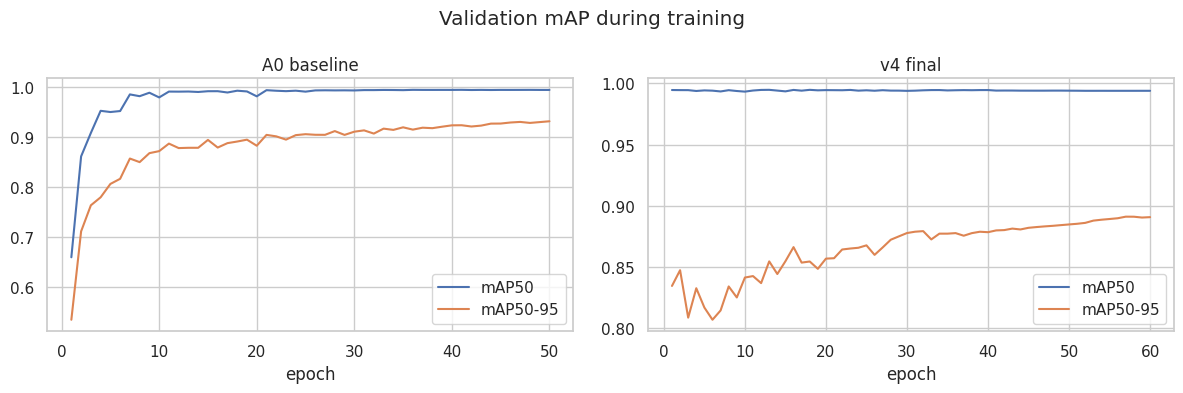

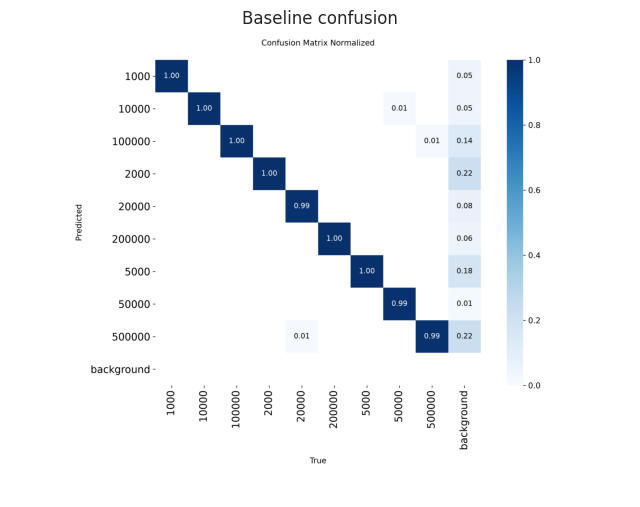

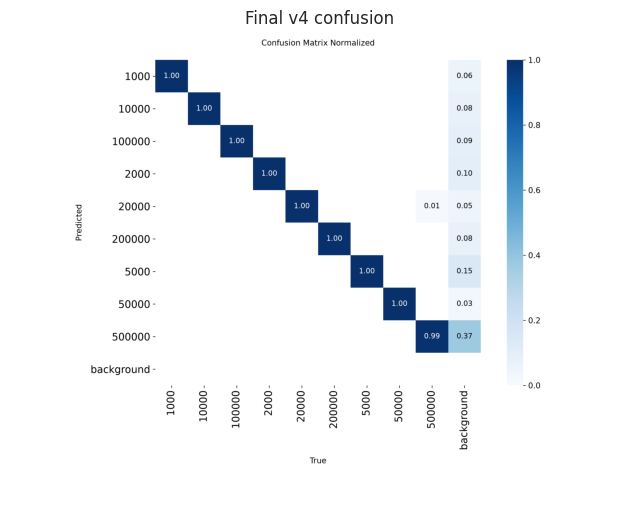

In [9]:
def load_history(run_name: str) -> pd.DataFrame | None:
    p = PROJECT_DIR / "runs" / "detect" / run_name / "results.csv"
    if not p.exists():
        print("Không tìm thấy tệp lịch sử huấn luyện:", p)
        return None
    df = pd.read_csv(p)
    df.columns = [c.strip() for c in df.columns]
    return df


hist_base = load_history("vn_currency_yolov8n_baseline")
hist_final = load_history("vn_currency_yolov8s_v4")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, label, ax in [
    (hist_base, "A0 baseline", axes[0]),
    (hist_final, "v4 final", axes[1]),
]:
    if hist is None:
        ax.set_title(f"{label}: chưa có results.csv")
        continue
    epoch = hist["epoch"] if "epoch" in hist.columns else hist.iloc[:, 0]
    map50 = next((c for c in hist.columns if "mAP50(B)" in c or ("mAP50" in c and "95" not in c)), None)
    map5095 = next((c for c in hist.columns if "mAP50-95" in c), None)
    if map50:
        ax.plot(epoch, hist[map50], label="mAP50")
    if map5095:
        ax.plot(epoch, hist[map5095], label="mAP50-95")
    ax.set_title(label)
    ax.set_xlabel("epoch")
    ax.legend()
plt.suptitle("Validation mAP during training")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_train_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Hiển thị confusion / PR đã xuất từ quá trình huấn luyện
for run, title in [
    ("vn_currency_yolov8n_baseline", "Baseline confusion"),
    ("vn_currency_yolov8s_v4", "Final v4 confusion"),
]:
    p = PROJECT_DIR / "runs" / "detect" / run / "confusion_matrix_normalized.png"
    if p.exists():
        plt.figure(figsize=(8, 7))
        plt.imshow(Image.open(p))
        plt.axis("off")
        plt.title(title)
        plt.show()


## 8. So sánh định tính trên ảnh Hard


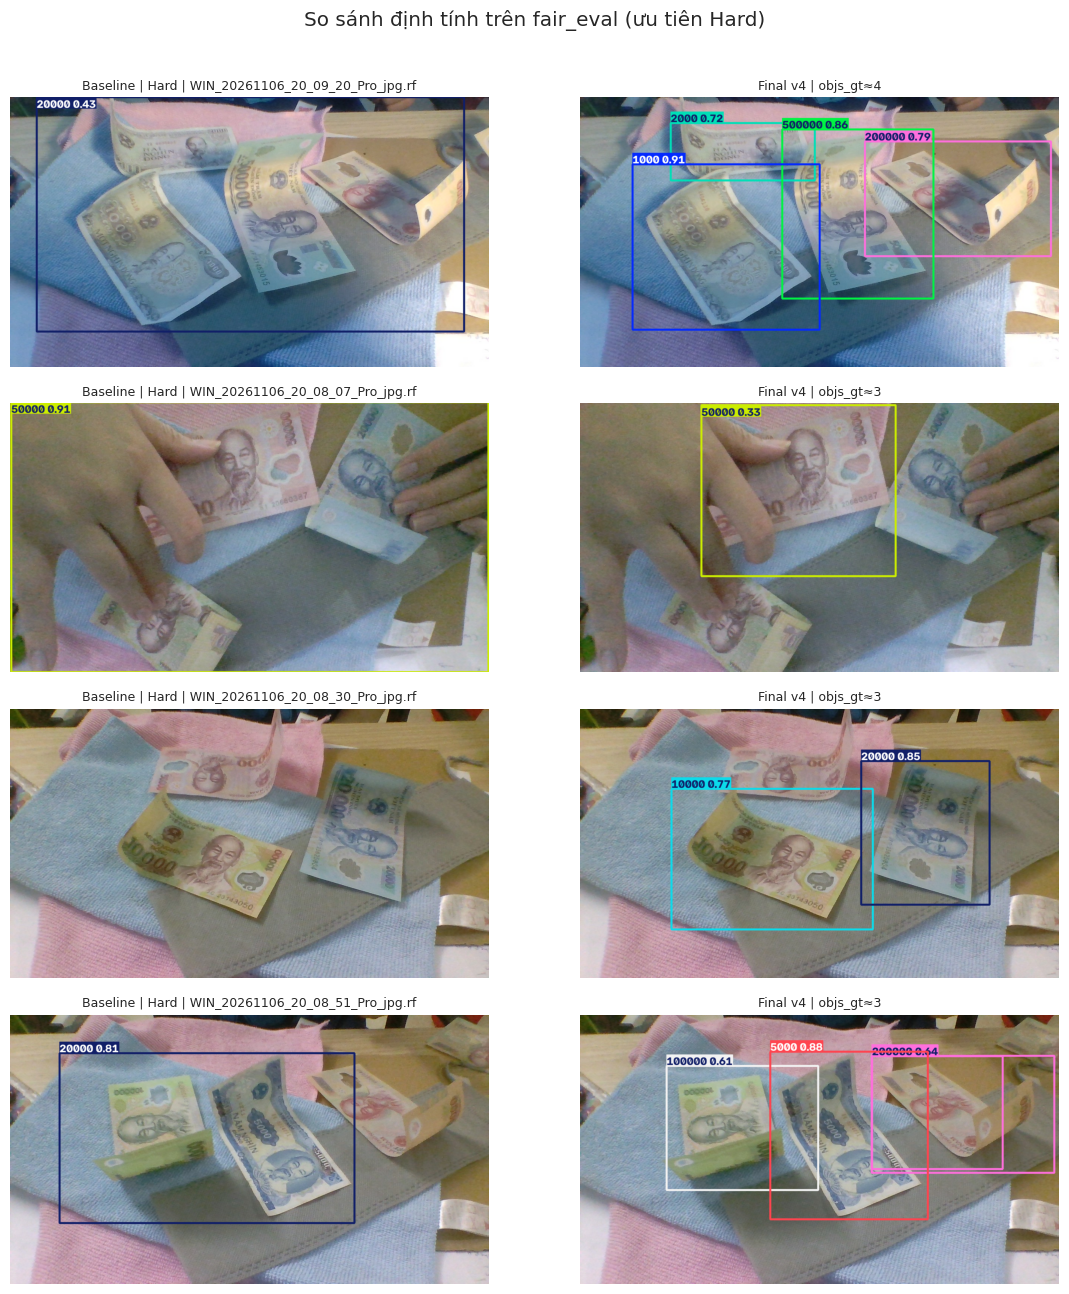

In [10]:
hard_img_dir = DATA_DIR / "hard" / "images"
normal_img_dir = DATA_DIR / "normal" / "images"
eval_lbl_dir = DATA_DIR / "labels"
hard_images = sorted(hard_img_dir.glob("*.jpg"))
normal_images = sorted(normal_img_dir.glob("*.jpg"))


def count_obj(stem: str) -> int:
    lp = eval_lbl_dir / f"{stem}.txt"
    if not lp.exists():
        return 0
    return sum(1 for ln in lp.read_text().splitlines() if ln.strip())


# Ưu tiên ảnh Hard có nhiều đối tượng; bổ sung Normal khi cần đủ mẫu quan sát
hard_ranked = sorted([(count_obj(p.stem), p) for p in hard_images], key=lambda x: -x[0])
sample = [p for _, p in hard_ranked[:4]]
if len(sample) < 4 and normal_images:
    sample += normal_images[: 4 - len(sample)]

base_model = YOLO(str(BASE_PT))
final_model = YOLO(str(FINAL_PT))

fig, axes = plt.subplots(len(sample), 2, figsize=(12, 3.2 * len(sample)))
if len(sample) == 1:
    axes = np.array([axes])

for i, path in enumerate(sample):
    b = base_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=EVAL_CONF, device=DEVICE, verbose=False)[0]
    f = final_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=EVAL_CONF, device=DEVICE, verbose=False)[0]
    tag = "Hard" if any(path.name == h.name for h in hard_images) else "Normal"
    axes[i, 0].imshow(b.plot()[:, :, ::-1])
    axes[i, 0].set_title(f"Baseline | {tag} | {path.name[:32]}", fontsize=9)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(f.plot()[:, :, ::-1])
    axes[i, 1].set_title(f"Final v4 | objs_gt≈{count_obj(path.stem)}", fontsize=9)
    axes[i, 1].axis("off")

plt.suptitle("So sánh định tính trên fair_eval (ưu tiên Hard)", y=1.01)
plt.tight_layout()
plt.savefig(EXPORT_DIR / "fig_qualitative_val.png", dpi=140, bbox_inches="tight")
plt.show()


### 8.1. Bổ sung quan sát trên các ảnh Hard khác


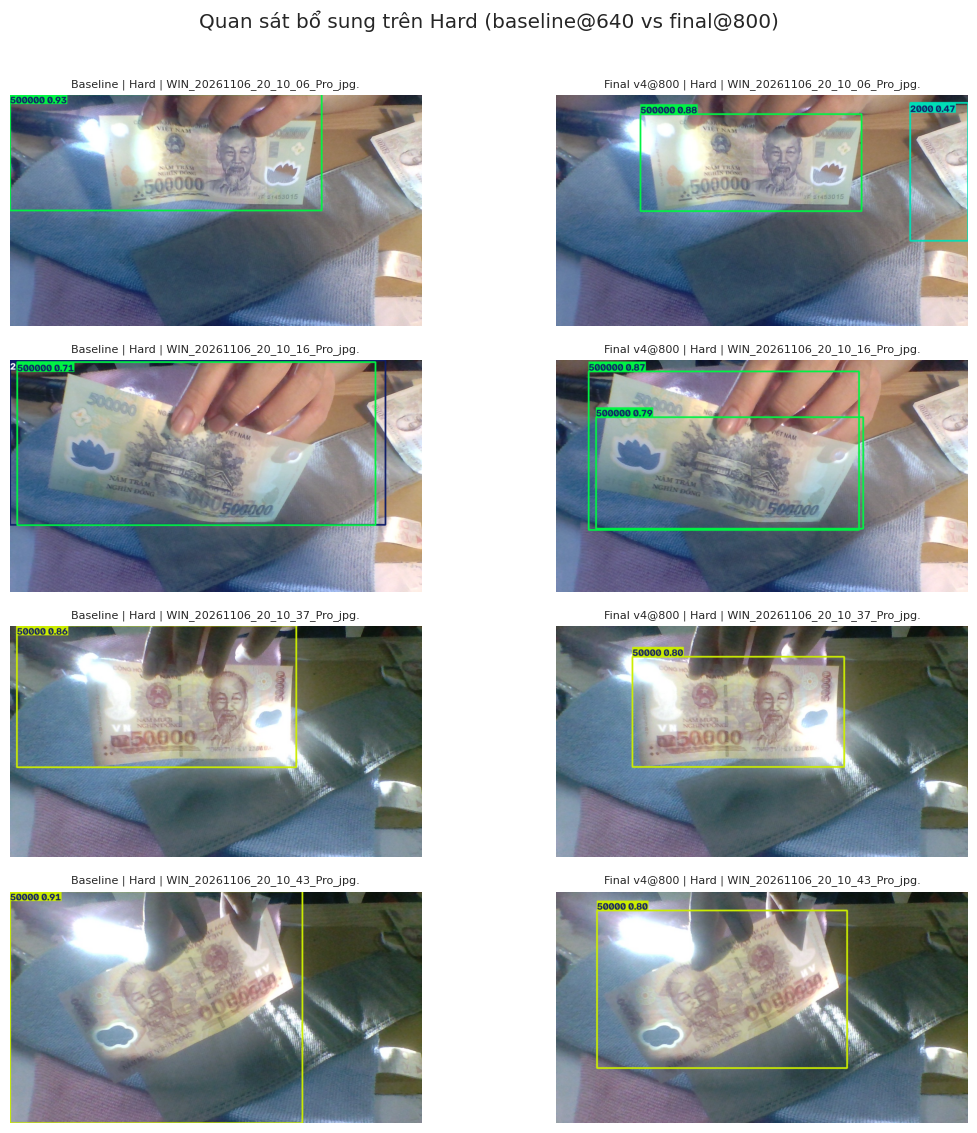

In [11]:
extra_hard = [p for p in hard_images if p not in sample][:4]
if extra_hard:
    fig, axes = plt.subplots(len(extra_hard), 2, figsize=(12, 2.8 * len(extra_hard)))
    if len(extra_hard) == 1:
        axes = np.array([axes])
    for i, path in enumerate(extra_hard):
        b = base_model.predict(str(path), imgsz=FAIR_IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
        f = final_model.predict(str(path), imgsz=DEPLOY_IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
        axes[i, 0].imshow(b.plot()[:, :, ::-1]); axes[i, 0].set_title(f"Baseline | Hard | {path.stem[:30]}", fontsize=8); axes[i, 0].axis("off")
        axes[i, 1].imshow(f.plot()[:, :, ::-1]); axes[i, 1].set_title(f"Final v4@800 | Hard | {path.stem[:30]}", fontsize=8); axes[i, 1].axis("off")
    plt.suptitle("Quan sát bổ sung trên Hard (baseline@640 vs final@800)", y=1.01)
    plt.tight_layout()
    plt.savefig(EXPORT_DIR / "fig_qualitative_real_cam.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("Không còn ảnh Hard ngoài mẫu đã trình bày.")


## 9. Tổng hợp nhận xét


In [12]:
summary = {
    "protocol": {
        "data_yaml": str(DATA_YAML),
        "fair_imgsz": FAIR_IMGSZ,
        "eval_conf": EVAL_CONF,
        "n_hard": N_HARD,
        "n_normal": N_NORMAL,
        "n_total": int(len(manifest)),
        "note": "fair_eval_hardmix: 16 Hard + 24 Normal (ảnh chụp thực); đánh giá độc lập sau khi khóa cấu hình",
    },
    "baseline_all": {k: base_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "final_all": {k: final_val[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "baseline_hard": {k: base_hard[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "final_hard": {k: final_hard[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "baseline_normal": {k: base_normal[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "final_normal": {k: final_normal[k] for k in ["mAP50", "mAP50-95", "precision", "recall", "f1"]},
    "delta_all_mAP50": final_val["mAP50"] - base_val["mAP50"],
    "delta_hard_mAP50": final_hard["mAP50"] - base_hard["mAP50"],
    "delta_hard_mAP50-95": final_hard["mAP50-95"] - base_hard["mAP50-95"],
    "improvements": [
        "Tăng dung lượng mạng: YOLOv8n → YOLOv8s",
        "Tăng cường dữ liệu mạnh (scale/mosaic/mixup/copy-paste/erasing) và xoay 90°",
        "Tái lấy mẫu các lớp dễ nhầm (5.000 / 20.000 / 200.000, …)",
        "Fine-tune đa vòng v2 → v3 → v4",
        "Bổ sung ảnh camera thực tế vào huấn luyện",
        "Cơ chế giữ nhãn theo thời gian (~1 s) trên luồng demo",
    ],
    "limitations": [
        "Quy mô fair_eval còn hạn chế (40 ảnh, trong đó 16 Hard) nên khoảng tin cậy thống kê còn rộng",
        "Một số cặp mệnh giá gần màu vẫn có thể nhầm trong điều kiện ánh sáng xấu",
        "Ảnh camera thực tế dùng fine-tune còn ít dù đã tăng cường",
        "Phạm vi lớp gồm chín mệnh giá; chưa phủ 500 đồng so với đặc tả đầy đủ",
    ],
}

with open(EXPORT_DIR / "compare_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

with open(REPORT_EXPORT / "compare_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("===== TỔNG HỢP CHỈ SỐ TRÊN fair_eval_hardmix =====")
print(
    f"Toàn bộ  mAP50: baseline={base_val['mAP50']:.4f} | final={final_val['mAP50']:.4f} | "
    f"Δ={final_val['mAP50']-base_val['mAP50']:+.4f}"
)
print(
    f"Hard     mAP50: baseline={base_hard['mAP50']:.4f} | final={final_hard['mAP50']:.4f} | "
    f"Δ={final_hard['mAP50']-base_hard['mAP50']:+.4f}"
)
print(
    f"Normal   mAP50: baseline={base_normal['mAP50']:.4f} | final={final_normal['mAP50']:.4f} | "
    f"Δ={final_normal['mAP50']-base_normal['mAP50']:+.4f}"
)
print(
    f"Hard   mAP50-95: baseline={base_hard['mAP50-95']:.4f} | final={final_hard['mAP50-95']:.4f} | "
    f"Δ={final_hard['mAP50-95']-base_hard['mAP50-95']:+.4f}"
)
print("Tệp tổng hợp:", EXPORT_DIR / "compare_summary.json")


===== TỔNG HỢP CHỈ SỐ TRÊN fair_eval_hardmix =====
Toàn bộ  mAP50: baseline=0.3994 | final=0.9293 | Δ=+0.5298
Hard     mAP50: baseline=0.1889 | final=0.8747 | Δ=+0.6858
Normal   mAP50: baseline=0.5732 | final=0.9554 | Δ=+0.3822
Hard   mAP50-95: baseline=0.0946 | final=0.5993 | Δ=+0.5047
Tệp tổng hợp: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/compare_exports/compare_summary.json
